# 03 Moving block bootstrap

Owner: Deng Shenbojia (A4, A5).

Implementation details, main result at l = 14, block-length sensitivity, side-by-side CIs.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

from src.data import load_daily
from src.strategy import build_series
from src.classical import t_test_mean
from src.bootstrap import mbb_ci, mbb_test

rng = np.random.default_rng(config.SEED)

## 1. How the block bootstrap works

Ordinary bootstrap randomly samples days one by one, disrupting the temporal order and effectively assuming daily independence. However, notebook 01 shows that d is not independent: its first-order autocorrelation is −0.11, and the Ljung–Box test rejects independence. Therefore, we sample a block of L consecutive days at once, preserving the relationships between days within each block. When L = 1, this reduces to the ordinary bootstrap.

If the block is too short, it cannot preserve enough correlation; if it is too long, there are too few blocks to choose from, leading to unstable results. A balance between the two is needed. Theory shows that when estimating the variance of the mean, the optimal block length grows at a rate of n^(1/3) (Hall, Horowitz & Jing, 1995). For n = 2,557, n^(1/3) ≈ 13.7, so we round it to 14. This value was fixed in config.py before any test was run, and Section 3 shows that other block lengths give the same conclusion.

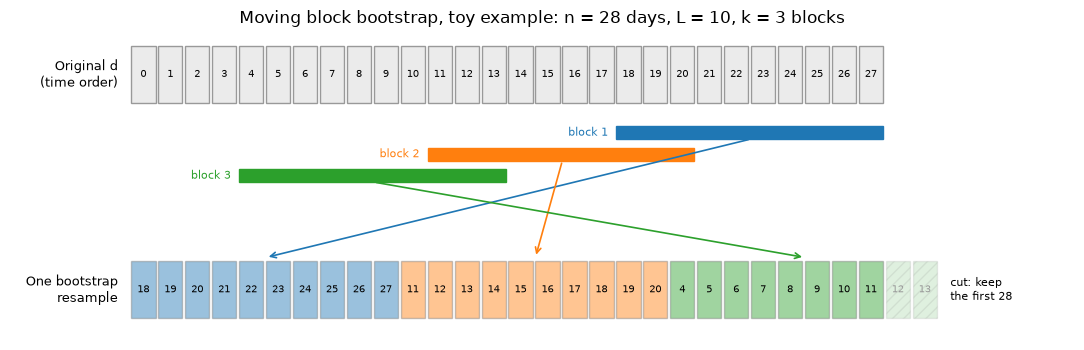

In [2]:
from matplotlib.patches import Rectangle
from src.bootstrap import mbb_indices

n_toy, L_toy = 28, 10  # toy size so every day is visible (the real run uses n = 2,557, L = 14)
idx_toy = mbb_indices(n_toy, L_toy, np.random.default_rng(52))  # one resample; seed 52 only for a readable picture
k_toy = int(np.ceil(n_toy / L_toy))  # 3 blocks
starts = idx_toy[::L_toy]  # first day of each block
colours = ["C0", "C1", "C2"]

fig, ax = plt.subplots(figsize=(11, 3.6))
for t in range(n_toy):  # top row: the original data, days 0 to 27 in time order
    ax.add_patch(Rectangle((t, 3), 0.9, 0.8, facecolor="0.92", edgecolor="0.6"))
    ax.text(t + 0.45, 3.4, str(t), ha="center", va="center", fontsize=7)
for j, s in enumerate(starts):  # coloured bar under the days that block j copies
    y = 2.5 - 0.3 * j
    ax.add_patch(Rectangle((s, y), L_toy - 0.1, 0.18, color=colours[j]))
    ax.text(s - 0.3, y + 0.09, f"block {j + 1}", ha="right", va="center", fontsize=8, color=colours[j])
    ax.annotate("", xy=(j * L_toy + L_toy / 2, 0.85), xytext=(s + L_toy / 2, y),
                arrowprops=dict(arrowstyle="->", color=colours[j], lw=1.2))
for pos in range(k_toy * L_toy):  # bottom row: the resample = blocks glued in the order drawn
    j = pos // L_toy
    cut = pos >= n_toy  # the last block overruns n, so these days are dropped
    ax.add_patch(Rectangle((pos, 0), 0.9, 0.8, facecolor=colours[j], alpha=0.15 if cut else 0.45,
                           edgecolor="0.5", hatch="///" if cut else None))
    ax.text(pos + 0.45, 0.4, str(starts[j] + pos % L_toy), ha="center", va="center", fontsize=7,
            color="0.6" if cut else "black")
ax.text(k_toy * L_toy + 0.4, 0.4, "cut: keep\nthe first 28", va="center", fontsize=8)
ax.text(-0.5, 3.4, "Original d\n(time order)", ha="right", va="center", fontsize=9)
ax.text(-0.5, 0.4, "One bootstrap\nresample", ha="right", va="center", fontsize=9)
ax.set_xlim(-4.5, k_toy * L_toy + 5)
ax.set_ylim(-0.3, 4)
ax.axis("off")
ax.set_title("Moving block bootstrap, toy example: n = 28 days, L = 10, k = 3 blocks")
fig.tight_layout()
fig.savefig(config.FIG_DIR / "03_block_diagram.png", dpi=150)
plt.show()

The toy example shows one resample: three blocks of 10 consecutive days are copied from random places in the series, joined in the order they were drawn, and the extra 2 days are cut so the resample has the original length. Blocks can overlap, and some days are not drawn at all, just as single days can repeat in the ordinary bootstrap. The real run does the same with n = 2,557, L = 14 and 183 blocks.

| Setting | Value | Where |
| --- | --- | --- |
| Block length | L = round(n^(1/3)) = round(2557^(1/3)) = round(13.68) = 14 | `config.BLOCK_LENGTH` |
| Blocks per resample | k = ceil(2557 / 14) = 183 blocks = 2,562 days, last 5 days cut | `mbb_indices` |
| Block starts | uniform on {0, ..., n - L} = {0, ..., 2543}, no wrap-around | `mbb_indices` |
| Resamples | B = 9,999, in batches of 1,000 | `config.B`, `mbb_means` |
| Seed | 607 | `config.SEED` |
| Interval | percentile 95% CI (2.5% and 97.5% quantiles); also mean ± 1.96 × SE | `mbb_ci` |
| Test | H0: mean = 0; p = (1 + #{abs(mean* − mean) ≥ abs(mean)}) / (B + 1) | `mbb_test` |

## 2. Main result (block length 14)

In [3]:
d = build_series(load_daily())["d"].to_numpy()  # daily excess return of the rule, 2,557 days
L = config.BLOCK_LENGTH  # pre-registered block length: round(2557 ** (1/3)) = 14

ci = mbb_ci(d, L)  # bootstrap SE and 95% intervals (B = 9,999, seed 607)
test = mbb_test(d, L)  # p-value for H0: mean of d = 0

main = pd.DataFrame([{
    "L": L,
    "B": ci["B"],
    "mean_d": ci["mean"],
    "boot_se": ci["se"],
    "ci_lo": ci["pct_lo"],  # percentile interval (main result)
    "ci_hi": ci["pct_hi"],
    "p": test["p"],
}])
config.TAB_DIR.mkdir(parents=True, exist_ok=True)  # outputs/tables/
main.to_csv(config.TAB_DIR / "03_main_result.csv", index=False)  # saved for README and slides
print(main.round(6).to_string(index=False))
print("95% CI contains 0:", ci["pct_lo"] < 0 < ci["pct_hi"])

 L    B    mean_d  boot_se     ci_lo    ci_hi      p
14 9999 -0.000208 0.000416 -0.001012 0.000617 0.6177
95% CI contains 0: True


With a block length of 14, the average daily excess return is −0.000208, and the 95% confidence interval is [−0.00101, 0.00062], with p = 0.62. The interval includes zero and the p-value is much greater than 0.05, so we cannot conclude that the rule's average daily return differs from buy-and-hold.

## 3. Sensitivity to the block length

 L  boot_se     ci_lo    ci_hi      p
 1 0.000476 -0.001132 0.000740 0.6613
 5 0.000445 -0.001058 0.000682 0.6380
10 0.000428 -0.001015 0.000662 0.6239
14 0.000416 -0.001012 0.000617 0.6177
20 0.000403 -0.000959 0.000625 0.6037
40 0.000377 -0.000914 0.000572 0.5785
t-test SE: 0.000475


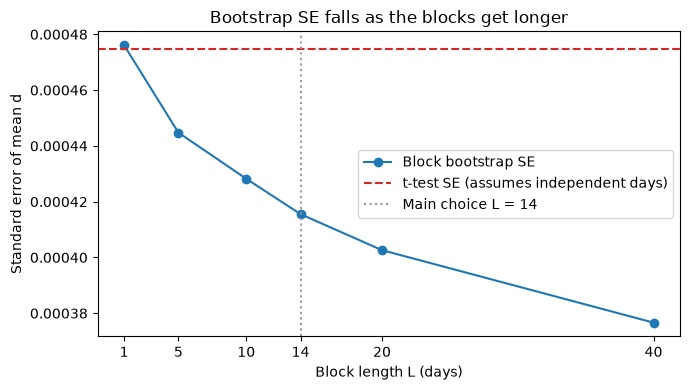

In [4]:
t_res = t_test_mean(d)  # Ma's t-test: reference line for the plot

rows = []
for L_i in config.BLOCK_GRID:  # [1, 5, 10, 14, 20, 40], fixed in config.py
    r = mbb_ci(d, L_i)  # same seed for every L, so only the block length changes
    rows.append({"L": L_i, "boot_se": r["se"], "ci_lo": r["pct_lo"], "ci_hi": r["pct_hi"], "p": mbb_test(d, L_i)["p"]})
sens = pd.DataFrame(rows)
sens.to_csv(config.TAB_DIR / "03_block_length_sensitivity.csv", index=False)
print(sens.round(6).to_string(index=False))
print("t-test SE:", round(t_res["se"], 6))

config.FIG_DIR.mkdir(parents=True, exist_ok=True)  # outputs/figures/
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sens["L"], sens["boot_se"], marker="o", color="C0", label="Block bootstrap SE")
ax.axhline(t_res["se"], color="C3", linestyle="--", label="t-test SE (assumes independent days)")
ax.axvline(L, color="0.6", linestyle=":", label="Main choice L = 14")
ax.set_xticks(config.BLOCK_GRID)
ax.set_xlabel("Block length L (days)")
ax.set_ylabel("Standard error of mean d")
ax.set_title("Bootstrap SE falls as the blocks get longer")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIG_DIR / "03_se_by_block_length.png", dpi=150)
plt.show()

When L = 1, the bootstrap standard error (SE) is almost identical to that of the t-test; as the block length increases, the SE decreases, and at L = 40 it is about 20% smaller than the t-test. Longer blocks keep more of the dependence between neighbouring days: because the first-order autocorrelation of d is negative (−0.11), positive and negative days partly cancel out, so the t-test, which ignores this, overestimates the uncertainty. All six intervals include zero, with p-values above 0.58, so the conclusion is robust to the choice of block length.

## 4. Bootstrap distribution of the mean

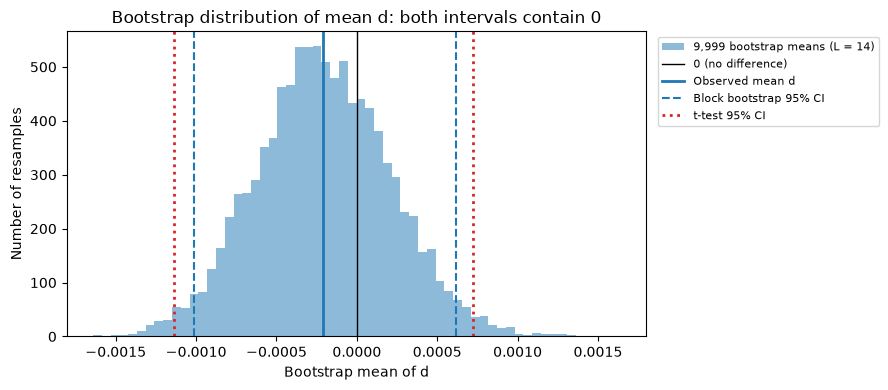

bootstrap CI width: 0.001629 | t-test CI width: 0.001862


In [5]:
from src.bootstrap import mbb_means

boot = mbb_means(d, L)  # the same 9,999 means that mbb_ci(d, 14) used (same seed 607)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(boot, bins=60, color="C0", alpha=0.5, label="9,999 bootstrap means (L = 14)")
ax.axvline(0, color="black", lw=1, label="0 (no difference)")
ax.axvline(ci["mean"], color="C0", lw=2, label="Observed mean d")
ax.axvline(ci["pct_lo"], color="C0", linestyle="--", label="Block bootstrap 95% CI")
ax.axvline(ci["pct_hi"], color="C0", linestyle="--")
ax.axvline(t_res["t_lo"], color="C3", linestyle=":", lw=2, label="t-test 95% CI")
ax.axvline(t_res["t_hi"], color="C3", linestyle=":", lw=2)
ax.set_xlabel("Bootstrap mean of d")
ax.set_ylabel("Number of resamples")
ax.set_title("Bootstrap distribution of mean d: both intervals contain 0")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))  # legend outside, so it hides no line
fig.tight_layout()
fig.savefig(config.FIG_DIR / "03_bootstrap_hist.png", dpi=150)
plt.show()
print("bootstrap CI width:", round(ci["pct_hi"] - ci["pct_lo"], 6), "| t-test CI width:", round(t_res["t_hi"] - t_res["t_lo"], 6))

The 9,999 bootstrap means are approximately bell-shaped around the observed mean, and zero lies well inside the distribution. The blue bootstrap interval is about 12% narrower than the red t-test interval (width 0.00163 vs. 0.00186), but both contain zero, so the two methods reach the same conclusion. The near-normal shape suggests the t-test's normal approximation is fine at 2,557 days; the difference between the methods comes from the standard error (autocorrelation), not from the shape of the distribution.

## 5. Side by side: t-test vs block bootstrap

In [6]:
from src.classical import variance_factor

side = pd.DataFrame([
    {"method": "t-test (independent days)", "mean_d": t_res["mean"], "se": t_res["se"],
     "ci_lo": t_res["t_lo"], "ci_hi": t_res["t_hi"], "p": t_res["p"]},
    {"method": "Block bootstrap (L = 14)", "mean_d": ci["mean"], "se": ci["se"],
     "ci_lo": ci["pct_lo"], "ci_hi": ci["pct_hi"], "p": test["p"]},
])
side["ci_width"] = side["ci_hi"] - side["ci_lo"]
side.to_csv(config.TAB_DIR / "03_side_by_side.csv", index=False)
print(side.round(6).to_string(index=False))

vf = variance_factor(d, L)  # Ma's formula: 1 + 2 x (weighted autocorrelations of d up to lag 14)
print("\nMa's variance factor (Bartlett, K = 14):", round(vf, 3))
print("SE predicted by the formula:", round(t_res["se"] * np.sqrt(vf), 6), "| bootstrap SE:", round(ci["se"], 6))
print("bootstrap SE / t-test SE:", round(ci["se"] / t_res["se"], 3), "| sqrt(factor):", round(np.sqrt(vf), 3))

                   method    mean_d       se     ci_lo    ci_hi        p  ci_width
t-test (independent days) -0.000208 0.000475 -0.001139 0.000723 0.661586  0.001862
 Block bootstrap (L = 14) -0.000208 0.000416 -0.001012 0.000617 0.617700  0.001629

Ma's variance factor (Bartlett, K = 14): 0.735
SE predicted by the formula: 0.000407 | bootstrap SE: 0.000416
bootstrap SE / t-test SE: 0.875 | sqrt(factor): 0.857


The means are the same, but the bootstrap SE is about 12% smaller (0.000416 vs. 0.000475), so its interval is narrower; both p-values exceed 0.6 and both intervals include zero. Why it is narrower: the first-order autocorrelation of d is negative, so the variance factor in Ma's formula (notebook 02) is 0.735, which predicts an SE of √0.735 × 0.000475 ≈ 0.000407, very close to the bootstrap's 0.000416; two different methods agreeing supports this explanation. So the t-test is somewhat conservative here, but after the correction the conclusion is unchanged: the rule's average daily return cannot be distinguished from buy-and-hold.